# T13 — Stage III sign-off artifact

**This is a SIGN-OFF / INTEGRATION notebook, not a new scientific implementation.**
Every computation below calls the already-implemented and already-approved T05–T12
components directly (`iste.step`, `iste.trajectory`, `iste.observation`,
`iste.forcing_ensemble`, `iste.ensemble_run`, `iste.diagnostics`, `iste.lookup_storage`,
and T12's `tests.test_stage3_validation` controlled cases). No second transport
implementation, no new KDE/source-attribution logic, and no Stage IV–VII code exists
here or anywhere in this repository.

## Backward-time sign convention (explicit)

Stage III integrates backward in time using `theta = t0 - t`, where `t0` is the
observation instant and `t` is physical (forward) time. As `theta` increases, `t`
*decreases* — every particle's recorded checkpoint timestamps in this notebook run
**backward** from `t0`: `t0, t0-dt, t0-2dt, ...`. The drift term is `-U` (never `+U`);
this is checked explicitly in §1 and was validated analytically in T12.

In [12]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.environment import load_field_dataset
from iste.observation import adapt_upstream_particles
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import run_ensemble, compute_diagnostics
from iste.lookup_storage import ParticleRecordStore
from iste.trajectory import run_backward_trajectory
from iste.geometry import metres_per_degree_longitude

from tests.test_stage3_validation import (
    run_all_cases, _invalid_step_setup, make_ocean, LAT, LON, T0 as SYN_T0, DT as SYN_DT,
    QUERY_LAT, ZERO_K,
)

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")

## A. Backward particle trajectories

A small (2-particle), real-data example (`data/ocean.nc`), 8 checkpoints. Checkpoint
timestamps decrease monotonically from `t0` -- confirmed explicitly below, not just
visually.

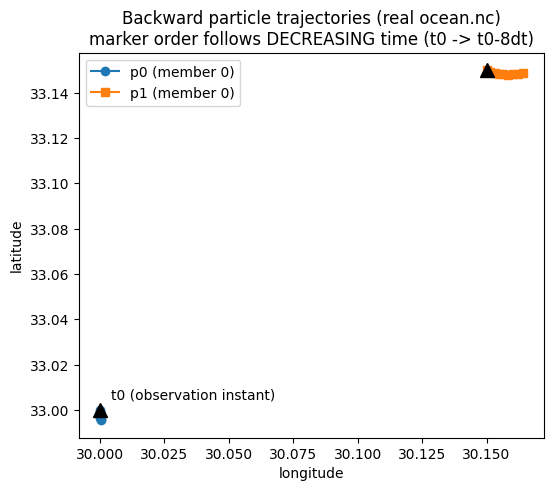

checkpoint timestamps (p0, member 0): [1570068000000000000, 1570067100000000000, 1570066200000000000, 1570065300000000000, 1570064400000000000, 1570063500000000000, 1570062600000000000, 1570061700000000000, 1570060800000000000]
strictly decreasing (backward in time): True


In [13]:
t0 = ocean.time[50]
particles = adapt_upstream_particles([
    {"particle_id": "p0", "latitude": 33.0, "longitude": 30.0, "observation_pixel_id": "px-0", "timestamp": t0},
    {"particle_id": "p1", "latitude": 33.15, "longitude": 30.15, "observation_pixel_id": "px-0", "timestamp": t0},
])
ensemble = ForcingEnsemble(ocean, ForcingEnsembleConfig(n_members=3, master_seed=7))
k_field = np.zeros((len(ocean.lat), len(ocean.lon)))
records = run_ensemble(particles, [0, 1], 8, 900.0, ocean, ensemble, ocean.lat, ocean.lon, k_field, master_seed=42)

fig, ax = plt.subplots(figsize=(6, 5))
for pid, style in [("p0", "o-"), ("p1", "s-")]:
    mask = (records.particle_id == pid) & (records.forcing_member_id == 0)
    ax.plot(records.lon[mask], records.lat[mask], style, label=f"{pid} (member 0)")
    ax.plot(records.lon[mask][0], records.lat[mask][0], "k^", markersize=10)
ax.annotate("t0 (observation instant)", (records.lon[records.particle_id == "p0"][0], records.lat[records.particle_id == "p0"][0]),
            textcoords="offset points", xytext=(8, 8))
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Backward particle trajectories (real ocean.nc)\nmarker order follows DECREASING time (t0 -> t0-8dt)")
ax.legend()
plt.show()

mask_p0_m0 = (records.particle_id == "p0") & (records.forcing_member_id == 0)
ts = records.timestamp[mask_p0_m0]
strictly_decreasing = bool(np.all(np.diff(ts.astype("int64")) < 0))
print(f"checkpoint timestamps (p0, member 0): {ts.tolist()}")
print(f"strictly decreasing (backward in time): {strictly_decreasing}")
assert strictly_decreasing

### Backward direction on a controlled, unambiguous synthetic field

Constant eastward `U`, `K=0`: the backward step must move the particle WEST -- the
exact case already validated analytically in T12 (`case_backward_sign_convention`).

In [14]:
sign_case = next(c for c in run_all_cases() if c.category == "backward sign convention")
print(f"{sign_case.name}\n  expected lon = {sign_case.expected:.6f}, computed lon = {sign_case.computed:.6f} "
      f"(started at 115.0 -- moved WEST as required)")
assert sign_case.passed

constant eastward U -> particle moves WEST by exactly -U*dt
  expected lon = 114.978467, computed lon = 114.978467 (started at 115.0 -- moved WEST as required)


## B. Weight evolution and its relationship to div(U)

Controlled case (reusing T12's exact setup, not a new implementation): a spatially
linear `U` gives a spatially CONSTANT `div(U)`, so the log-weight must fall exactly on
the line `log_w(n) = -div(U) * dt * n`. This directly demonstrates the weight ODE
`d(ln w)/d(theta) = -div(U)`.

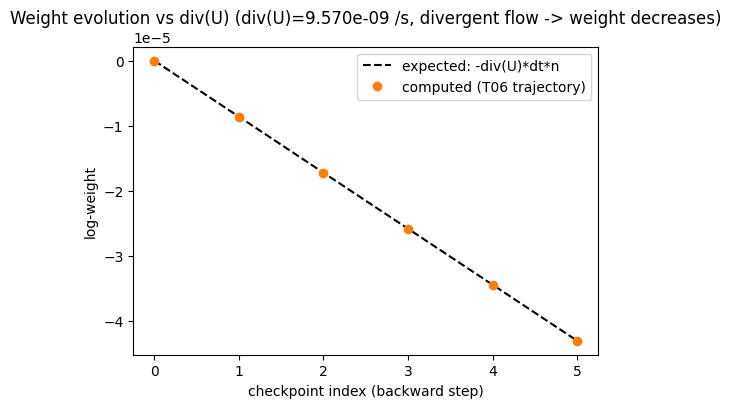

max |computed - expected| across all checkpoints: 0.000e+00


In [15]:
C = 0.001
uo_grid = C * (LON[None, :] - 115.0) * np.ones((3, 1))  # divergent (du/dx > 0)
ocean_div = make_ocean(uo_grid, np.zeros((3, 7)))
n_steps = 5
rng = np.random.default_rng(108)
traj_w = run_backward_trajectory(QUERY_LAT, 115.0, SYN_T0, n_steps, SYN_DT, ocean_div, LAT, LON, ZERO_K, rng, log_weight0=0.0)

expected_div = C / metres_per_degree_longitude(QUERY_LAT)
steps_w = np.arange(traj_w.n_states)
expected_line = -expected_div * SYN_DT * steps_w

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(steps_w, expected_line, "k--", label="expected: -div(U)*dt*n")
ax.plot(steps_w, traj_w.log_weight, "o", color="tab:orange", label="computed (T06 trajectory)")
ax.set_xlabel("checkpoint index (backward step)")
ax.set_ylabel("log-weight")
ax.set_title(f"Weight evolution vs div(U) (div(U)={expected_div:.3e} /s, divergent flow -> weight decreases)")
ax.legend()
plt.show()

max_err = float(np.max(np.abs(traj_w.log_weight - expected_line)))
print(f"max |computed - expected| across all checkpoints: {max_err:.3e}")
assert max_err < 1e-9

### Real-data weight evolution (sanity check only, not analytic validation)

Same real-data run as §A -- weight stays close to 1.0 (real `div(U)` is small at this
location/window), shown only to confirm the machinery behaves sensibly on real data, not
as ground truth.

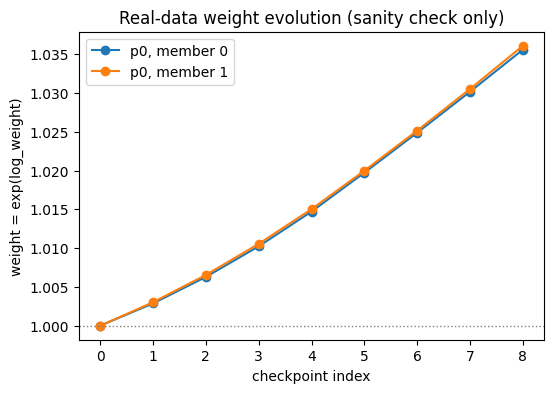

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
for member_id in (0, 1):
    mask = (records.particle_id == "p0") & (records.forcing_member_id == member_id)
    ax.plot(np.arange(np.sum(mask)), np.exp(records.log_weight[mask]), "o-", label=f"p0, member {member_id}")
ax.axhline(1.0, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("checkpoint index"); ax.set_ylabel("weight = exp(log_weight)")
ax.set_title("Real-data weight evolution (sanity check only)")
ax.legend()
plt.show()

## C. Validity / boundary handling

One particle that stays valid throughout, and one that becomes invalid partway (exactly
at the analytically predicted step, per T12) -- both retained in full, never dropped.

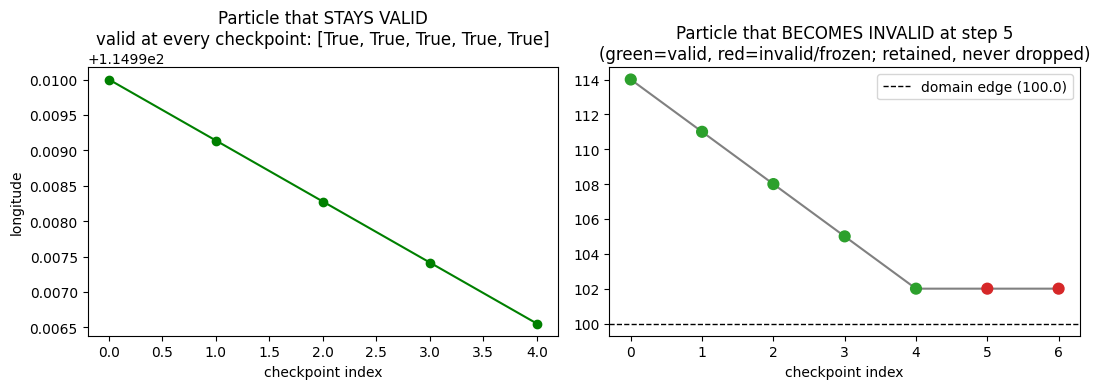

stays-valid particle: 5 states recorded, all valid: True
becomes-invalid particle: 7 states recorded (== n_steps+1, never truncated), first_invalid_index=5, all states after that stay invalid: True


In [17]:
# stays valid
ocean_ok = make_ocean(np.full((3, 7), 0.1), np.zeros((3, 7)))
rng = np.random.default_rng(200)
traj_valid = run_backward_trajectory(QUERY_LAT, 115.0, SYN_T0, 4, SYN_DT, ocean_ok, LAT, LON, ZERO_K, rng)

# becomes invalid at the exact predicted step (T12's case, reused directly)
traj_invalid = _invalid_step_setup()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(traj_valid.n_states), traj_valid.lon, "go-")
axes[0].set_title(f"Particle that STAYS VALID\nvalid at every checkpoint: {traj_valid.valid.tolist()}")
axes[0].set_xlabel("checkpoint index"); axes[0].set_ylabel("longitude")

colors = ["tab:green" if v else "tab:red" for v in traj_invalid.valid]
axes[1].plot(np.arange(traj_invalid.n_states), traj_invalid.lon, "-", color="gray", zorder=1)
axes[1].scatter(np.arange(traj_invalid.n_states), traj_invalid.lon, c=colors, zorder=2, s=60)
axes[1].axhline(LON.min(), color="black", linestyle="--", linewidth=1, label=f"domain edge ({LON.min()})")
axes[1].set_title(f"Particle that BECOMES INVALID at step {traj_invalid.first_invalid_index}\n"
                   f"(green=valid, red=invalid/frozen; retained, never dropped)")
axes[1].set_xlabel("checkpoint index"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"stays-valid particle: {traj_valid.n_states} states recorded, all valid: {bool(np.all(traj_valid.valid))}")
print(f"becomes-invalid particle: {traj_invalid.n_states} states recorded (== n_steps+1, never truncated), "
      f"first_invalid_index={traj_invalid.first_invalid_index}, "
      f"all states after that stay invalid: {bool(np.all(~traj_invalid.valid[traj_invalid.first_invalid_index:]))}")
assert traj_invalid.n_states == 7  # not silently truncated
assert bool(np.all(traj_valid.valid))

## D. Small Stage III lookup-table sample

A small sample of `c_hat*_{j,e}(x,t)` transport-estimate records from the §A real-data
run, stored via T11's `ParticleRecordStore` and retrieved by observation pixel. **This is
a weighted Monte Carlo transport estimate, not an exact probability or proof of source**
-- each row is one particle's position/weight at one checkpoint under one forcing-member
realization, not a probability density.

In [18]:
store = ParticleRecordStore()
store.add_records(records)
sample = store.records_for_pixel("px-0")

lookup_table_sample = pd.DataFrame({
    "particle_id": sample.particle_id[:8],
    "forcing_member_id": sample.forcing_member_id[:8],
    "observation_pixel_id": sample.observation_pixel_id[:8],
    "timestamp": sample.timestamp[:8],
    "lat": np.round(sample.lat[:8], 4),
    "lon": np.round(sample.lon[:8], 4),
    "particle_weight (exp(log_weight))": np.round(np.exp(sample.log_weight[:8]), 4),
    "valid": sample.valid[:8],
})
print("c_hat*_{j,e}(x,t) SAMPLE -- Monte Carlo transport estimate, NOT an exact probability or proof of source:")
lookup_table_sample

c_hat*_{j,e}(x,t) SAMPLE -- Monte Carlo transport estimate, NOT an exact probability or proof of source:


,particle_id,forcing_member_id,observation_pixel_id,timestamp,lat,lon,particle_weight (exp(log_weight)),valid
0,p0,0,px-0,2019-10-03 02:00:00,33.0000,30.0000,1.0000,True
1,p0,0,px-0,2019-10-03 01:45:00,32.9993,30.0000,1.0029,True
2,p0,0,px-0,2019-10-03 01:30:00,32.9986,30.0000,1.0063,True
3,p0,0,px-0,2019-10-03 01:15:00,32.9979,30.0000,1.0102,True
4,p0,0,px-0,2019-10-03 01:00:00,32.9973,30.0000,1.0147,True
5,p0,0,px-0,2019-10-03 00:45:00,32.9968,30.0001,1.0197,True
6,p0,0,px-0,2019-10-03 00:30:00,32.9963,30.0002,1.0249,True
7,p0,0,px-0,2019-10-03 00:15:00,32.9959,30.0002,1.0302,True


### Round-trip check (T11) and diagnostics (T10) on this run

In [19]:
all_from_store = store.all_records()
round_trip_ok = (
    all_from_store.n_records == records.n_records
    and np.array_equal(all_from_store.log_weight, records.log_weight)
    and np.array_equal(all_from_store.valid, records.valid)
)
print(f"lookup-table round trip preserves all {records.n_records} records exactly: {round_trip_ok}")
assert round_trip_ok

diag = compute_diagnostics(records)
print(f"diagnostics (final checkpoint, this small run): {diag}")

lookup-table round trip preserves all 36 records exactly: True
diagnostics (final checkpoint, this small run): StageIIIDiagnostics(total_particles=4, valid_particles=4, invalid_particles=0, total_weight=4.1041867755556165, effective_sample_size=3.9995470270262685, valid_particle_fraction=1.0)


## Compact summary table

In [20]:
rows = []
for c in run_all_cases():
    rows.append({
        "Test/case": f"[{c.category}] {c.name}",
        "Expected behavior": f"{c.expected:.6g}",
        "Observed behavior": f"{c.computed:.6g}",
        "Pass/Fail": "PASS" if c.passed else "FAIL",
        "Relevant diagnostics": f"error={c.error:.2e}, tol={c.tolerance:.1e}",
    })

rows.append({
    "Test/case": "[T13 integration] backward checkpoint timestamps strictly decrease (real data)",
    "Expected behavior": "True", "Observed behavior": str(strictly_decreasing),
    "Pass/Fail": "PASS" if strictly_decreasing else "FAIL",
    "Relevant diagnostics": f"n_checkpoints={len(ts)}",
})
rows.append({
    "Test/case": "[T13 integration] stays-valid particle remains valid at every checkpoint",
    "Expected behavior": "True", "Observed behavior": str(bool(np.all(traj_valid.valid))),
    "Pass/Fail": "PASS" if bool(np.all(traj_valid.valid)) else "FAIL",
    "Relevant diagnostics": f"n_states={traj_valid.n_states}",
})
invalid_ok = traj_invalid.n_states == 7 and traj_invalid.first_invalid_index == 5
rows.append({
    "Test/case": "[T13 integration] invalid particle retained (not truncated), correct first-invalid step",
    "Expected behavior": "n_states=7, first_invalid=5",
    "Observed behavior": f"n_states={traj_invalid.n_states}, first_invalid={traj_invalid.first_invalid_index}",
    "Pass/Fail": "PASS" if invalid_ok else "FAIL",
    "Relevant diagnostics": "see \u00a7C",
})
rows.append({
    "Test/case": "[T13 integration, REAL-DATA SANITY CHECK ONLY] small real run: lookup-table round trip exact",
    "Expected behavior": "True", "Observed behavior": str(round_trip_ok),
    "Pass/Fail": "PASS" if round_trip_ok else "FAIL",
    "Relevant diagnostics": str(diag),
})

summary_table = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
n_pass = int((summary_table["Pass/Fail"] == "PASS").sum())
print(f"{n_pass} / {len(summary_table)} rows PASS")
summary_table

16 / 16 rows PASS


,Test/case,Expected behavior,Observed behavior,Pass/Fail,Relevant diagnostics
0,[zero divergence] uniform U -> log-weight unchanged,1.5,1.5,PASS,"error=0.00e+00, tol=1.0e-09"
1,[backward sign convention] constant eastward U -> particle moves WEST by exactly -U*dt,114.978,114.978,PASS,"error=0.00e+00, tol=1.0e-09"
2,[known convergent flow] div(U)<0 -> log-weight increases by exactly -div(U)*dt,8.61334e-06,8.61334e-06,PASS,"error=0.00e+00, tol=1.0e-09"
3,[known divergent flow] div(U)>0 -> log-weight decreases by exactly -div(U)*dt,-8.61334e-06,-8.61334e-06,PASS,"error=0.00e+00, tol=1.0e-09"
4,[constant diffusivity K] grad(K)=0 for a spatially constant K field,0,1.84465e-20,PASS,"error=1.84e-20, tol=1.0e-09"
5,"[constant diffusivity K] U=0, constant K -> displacement == sqrt(2*K*dt)*xi exactly",115.002,115.002,PASS,"error=0.00e+00, tol=1.0e-09"
6,[spatially varying diffusivity K] numerical grad(K) matches analytic gradient for a li...,0.000957038,0.000957038,PASS,"error=0.00e+00, tol=1.0e-09"
7,[spatially varying diffusivity K] T05 step reproduces the expected +grad(K)*dt drift (...,115,115,PASS,"error=0.00e+00, tol=1.0e-09"
8,[particle validity] valid destination at every step -> particle stays valid,1,1,PASS,"error=0.00e+00, tol=0.0e+00"
9,[particle validity] leaving the domain marks the particle invalid at the exact predict...,5,5,PASS,"error=0.00e+00, tol=0.0e+00"


## grad(K) contribution and div(U) sign-convention recap

Already demonstrated analytically in T12 and reused here directly (not recomputed with a
second implementation):

- **grad(K) contribution is present where applicable**: T12's `spatially varying
  diffusivity K` cases (rows above) confirm both that T03's numerical `grad(K)` matches
  the exact analytic gradient of a linear K field, and that T05's step reproduces the
  expected `+grad(K)*dt` drift contribution exactly.
- **div(U) controls the weight update with the tested sign convention**: T12's
  `known convergent flow`/`known divergent flow` cases (rows above), plus §B's multi-step
  line-fit, confirm `log_w_new = log_w_old - div(U)*dt` exactly -- convergent flow
  (`div(U)<0`) increases weight, divergent flow (`div(U)>0`) decreases it.
- **Diagnostics are available**: §D shows `iste.diagnostics`/`iste.ensemble_run`'s
  `total_particles`, `valid_particles`, `invalid_particles`, `total_weight`,
  `effective_sample_size`, `valid_particle_fraction` computed on this run.

## E. Environmental field interface (`EnvironmentalFieldProvider`) — now fully wired

**Fix applied after the first T13 review**: `NetCDFEnvironmentalFieldProvider.K`/
`grad_K`/`div_U` previously raised `NotImplementedError` even though the live T05
pipeline already computed the same quantities internally. They are now implemented via
two small shared helpers, `iste.environment.interpolated_divergence` and
`interpolated_k_value_and_gradient`, built on T03's `divergence_2d`/`spatial_gradient`
and T02's interpolation -- **`iste.step.backward_euler_maruyama_step` was refactored to
call these exact same two helpers instead of its own inline copy of the same math**, so
the provider interface and the live pipeline are now provably the same implementation,
not two independent ones. No Stage III equation changed; every existing T05/T06 test
(hand-computed expectations, unmodified) still passes.

Demonstrated below: `U`, `validity`, and `div_U` work with no `K` configured (they don't
need it); `K`/`grad_K` raise a clear, explicit configuration error with no `K` supplied,
and work correctly once one is; `validity` agrees with T04's own domain check; `div_U`
agrees with what T05's live step function actually computes for the same input.

In [21]:
from iste.environment import NetCDFEnvironmentalFieldProvider, GriddedFieldSource
from iste.boundary import netcdf_validity_check
from iste.step import WeightedParticleState, backward_euler_maruyama_step

# -- U, validity, div_U: work with NO K configured --------------------------------------
provider_no_k = NetCDFEnvironmentalFieldProvider(ocean)
x, t = np.array([30.0, 33.0]), t0  # (lon, lat)
u_val = provider_no_k.U(x, t)
valid_val = provider_no_k.validity(x, t)
div_val = provider_no_k.div_U(x, t)
print(f"provider.U({x.tolist()}, t0)        = {u_val}")
print(f"provider.validity({x.tolist()}, t0) = {valid_val}")
print(f"provider.div_U({x.tolist()}, t0)    = {div_val:.6e}")

# validity must agree with T04's own domain check for the same point
t04_check = netcdf_validity_check(ocean, "uo", t)
t04_valid = bool(t04_check(np.array([33.0]), np.array([30.0]))[0])
print(f"agrees with T04's netcdf_validity_check: {valid_val == t04_valid}")
assert valid_val == t04_valid

# K/grad_K raise a CLEAR configuration error, not a silent default, when unconfigured
try:
    provider_no_k.K(x, t)
    raise AssertionError("expected ValueError")
except ValueError as exc:
    print(f"provider.K with no K configured raises ValueError: {str(exc)[:70]}...")

# -- K, grad_K: work once a K grid is explicitly supplied --------------------------------
k_lat, k_lon = ocean.lat, ocean.lon
k_slope = 100.0  # PROTOTYPE synthetic test field, not a physical claim
k_lon_ref = float(k_lon[len(k_lon) // 2])
k_field_supplied = k_slope * (k_lon[None, :] - k_lon_ref) * np.ones((len(k_lat), 1))
provider_with_k = NetCDFEnvironmentalFieldProvider(ocean, k_lat=k_lat, k_lon=k_lon, k_field=k_field_supplied)

lon_q = k_lon_ref + 1.0
k_result = provider_with_k.K(np.array([lon_q, 33.0]), t)
grad_k_result = provider_with_k.grad_K(np.array([lon_q, 33.0]), t)
analytic_dKdx = k_slope / metres_per_degree_longitude(33.0)
print(f"\nprovider.K = {k_result:.4f} (supplied K at this point)")
print(f"provider.grad_K = {grad_k_result} vs analytic dK/dx = {analytic_dKdx:.6e} (exact linear field)")
assert np.isclose(grad_k_result[0], analytic_dKdx, atol=1e-6)

# -- div_U: matches what T05's LIVE step function actually computes ----------------------
# same controlled synthetic field as tests/test_step.py's convergent-flow case
lat_grid = np.array([10.0, 20.0, 30.0]); lon_grid = np.array([100.0, 110.0, 120.0])
time_grid = np.array(["2020-01-01T00:00", "2020-01-01T01:00"], dtype="datetime64[ns]")
C = 0.001
uo_grid = -C * lon_grid[None, :] * np.ones((3, 1))
synth_ocean = GriddedFieldSource(
    source_path="<synthetic>", time_name="time", time=time_grid, lat_name="lat", lat=lat_grid,
    lon_name="lon", lon=lon_grid,
    data={"uo": np.stack([uo_grid, uo_grid]), "vo": np.stack([np.zeros((3, 3))] * 2)}, fill_threshold=1e19,
)
provider_synth = NetCDFEnvironmentalFieldProvider(synth_ocean)
provider_div = provider_synth.div_U(np.array([110.0, 20.0]), time_grid[0])

state = WeightedParticleState.initialize(lat0=[20.0], lon0=[110.0])
rng = np.random.default_rng(6)
t05_new_state = backward_euler_maruyama_step(
    state, time_grid[0], 900.0, synth_ocean, lat_grid, lon_grid, np.zeros((3, 3)), rng
)
t05_implied_div = -float(t05_new_state.log_weight[0]) / 900.0  # log_w = -div(U)*dt with log_w0=0
print(f"\nprovider.div_U            = {provider_div:.6e}")
print(f"T05 step's own implied div = {t05_implied_div:.6e}  (from -log_weight/dt)")
print(f"agree exactly: {np.isclose(provider_div, t05_implied_div)}")
assert np.isclose(provider_div, t05_implied_div)

provider.U([30.0, 33.0], t0)        = [0.02573462 0.10167018]
provider.validity([30.0, 33.0], t0) = True
provider.div_U([30.0, 33.0], t0)    = -2.552431e-06
agrees with T04's netcdf_validity_check: True
provider.K with no K configured raises ValueError: K was not configured for this provider. Stage III v1 has no physically...

provider.K = 100.0000 (supplied K at this point)
provider.grad_K = [0.00107232 0.        ] vs analytic dK/dx = 1.072318e-03 (exact linear field)

provider.div_U            = -9.570381e-09
T05 step's own implied div = -9.570381e-09  (from -log_weight/dt)
agree exactly: True


## Stage III Definition of Done -- checklist against `tasks.md`

In [22]:
dod_rows = [
    ("Environmental field interface exposes U, K, grad(K), div(U), validity",
     "DONE -- all five now functional via NetCDFEnvironmentalFieldProvider (see §E; "
     "fixed after the first T13 review)"),
    ("Spatial (bilinear) + temporal (linear) interpolation, tested separately (T02)", "DONE"),
    ("Metre/degree conversions explicit, never mixed directly (T03)", "DONE"),
    ("Backward SDE step + weight ODE implemented, sign convention documented (T05)", "DONE"),
    ("Boundary/validity policy explicit, particles never silently lost (T04)", "DONE"),
    ("Forcing-ensemble perturbation mechanism documented + implemented (T08)",
     "DONE -- explicitly PROTOTYPE, NOT VALIDATED (see below)"),
    ("Particle records retain observation_pixel_id/forcing_member_id/weight/validity + "
     "lookup-table storage (T07/T09/T11)", "DONE"),
    ("Diagnostics implemented and tested (T10)", "DONE"),
    ("Controlled numerical validation suite (T12) passes", "DONE (approved)"),
    ("Human-inspectable sign-off artifact (T13) exists and manually approved",
     "ARTIFACT EXISTS -- approval is PENDING (this notebook)"),
    ("Stage IV-VII remain unimplemented and unplanned in detail", "DONE (confirmed)"),
]
pd.DataFrame(dod_rows, columns=["Definition-of-Done item", "Status"])

,Definition-of-Done item,Status
0,"Environmental field interface exposes U, K, grad(K), div(U), validity",DONE -- all five now functional via NetCDFEnvironmentalFieldProvider (see §E; fixed af...
1,"Spatial (bilinear) + temporal (linear) interpolation, tested separately (T02)",DONE
2,"Metre/degree conversions explicit, never mixed directly (T03)",DONE
3,"Backward SDE step + weight ODE implemented, sign convention documented (T05)",DONE
4,"Boundary/validity policy explicit, particles never silently lost (T04)",DONE
5,Forcing-ensemble perturbation mechanism documented + implemented (T08),"DONE -- explicitly PROTOTYPE, NOT VALIDATED (see below)"
6,Particle records retain observation_pixel_id/forcing_member_id/weight/validity + looku...,DONE
7,Diagnostics implemented and tested (T10),DONE
8,Controlled numerical validation suite (T12) passes,DONE (approved)
9,Human-inspectable sign-off artifact (T13) exists and manually approved,ARTIFACT EXISTS -- approval is PENDING (this notebook)


### Previously-flagged gap — now RESOLVED (interface-integration fix)

The first review of this sign-off notebook found that
`iste.environment.NetCDFEnvironmentalFieldProvider` implemented `U` and `validity` but
had `K`, `grad_K`, and `div_U` raise `NotImplementedError`, even though the live T05
pipeline already computed the same quantities internally via `iste.derivatives`/
`iste.interpolation` directly. That gap is fixed (see §E above):

- `div_U` and `grad_K` are now implemented via two small shared helper functions,
  `iste.environment.interpolated_divergence` and `interpolated_k_value_and_gradient`
  (built on T03's `divergence_2d`/`spatial_gradient` and T02's interpolation) — **not** a
  second, independent implementation.
- `iste.step.backward_euler_maruyama_step` (T05) was refactored to call these exact same
  two helpers instead of its own inline copy of the same math, so the provider interface
  and the live pipeline are now provably backed by one implementation. §E demonstrates
  `provider.div_U` matching T05's own live step output exactly for the same input.
- `K` remains externally supplied only — no physical formula was invented. If no `K` grid
  is passed to the constructor, `K`/`grad_K` raise a clear `ValueError` explaining exactly
  that, rather than a silent default or a generic `NotImplementedError`.
- No Stage III equation changed, and no T05/T06 test's hand-computed expectation changed
  — the existing, unmodified `tests/test_step.py`/`tests/test_trajectory.py` suites still
  pass exactly as before.

## Final interpretation (read this section)

**Stage III is a validated prototype transport component, not a standalone proof of
source location. The posterior source inference is performed in later stages.**

- Stage III's backward-adjoint SDE, weight ODE, boundary/validity policy, forcing-
  ensemble injection, diagnostics, lookup-table storage, and environmental field
  interface have each been validated against controlled synthetic cases with known
  analytic answers (T12, reused directly above) and exercised end-to-end on small
  real-data cases (this notebook, §A-E).
- The `c_hat*_{j,e}(x,t)` records shown in §D are a **weighted Monte Carlo transport
  estimate** -- a sample of particle positions and weights under sampled forcing
  realizations -- **not** a probability density, and not a KDE. No kernel density
  estimate or transport concentration is computed anywhere in this repository, and none
  is treated as proof of the physical spill source.
- **Stage III alone has not confirmed, and does not claim to confirm, any spill
  source.** Turning these weighted transport samples into a source-location posterior
  requires the surrogate likelihood (Stage IV), tempered SMC (Stage V), delayed-
  acceptance MCMC (Stage VI), and the time-indexed posterior/AIS-ready output
  (Stage VII) -- none of which are implemented, planned in detail, or approximated
  anywhere in this repository.
- The forcing ensemble (T08) remains an explicitly labeled **PROTOTYPE, NOT VALIDATED**
  surrogate (20 km spatial correlation / 1 day correlation time / 0.05 m/s amplitude) --
  sign-off of the Stage III *engine* does not constitute validation of these physical
  parameter values.
- The environmental-field-interface gap flagged in the first review of this notebook
  (`NetCDFEnvironmentalFieldProvider.K`/`grad_K`/`div_U` stubs) has been fixed -- see §E
  and "Previously-flagged gap -- now RESOLVED" above -- by wiring the provider to the
  same shared helpers the live T05 pipeline now also calls, with no equation change.

This notebook, once you approve it, is the Stage III sign-off gate per `README.md`/
`CLAUDE.md`. Stage IV work may only begin after that approval.